**Лабораторная работа №2**  
Дисциплина: Системы искусственного интеллекта и машинное обучение

### Автор
* **ФИО:** Коваленко Евгений Алексеевич
* **Группа:** АП-327

**Датасет:** Telco Customer Churn 

**Датасет** дает информацию о пользователях компании Telco: какими сервисами они пользовались, информация об их аккаунте, демографическая информация (пол, возраст, наличие партнера) и то, перестали ли они пользоваться услугами компании в прошлом месяце.

**Цель работы**: изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

**Постановка задачи:**

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:
- Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB);
- Деревья решений (Decision Tree);
- Линейный дискриминантный анализ (Linear Discriminant Analysis);
- Метод опорных векторов (Support Vector Machines);
- Метод ближайших соседей (k-Nearest Neighbors);
2. Сравнить качество работы классификаторов с помощью следующих метрик:
- Accuracy (точность),
- Precision (доля правильно классифицированных положительных примеров),
- Recall (чувствительность, доля верно найденных положительных примеров),
- F1-Score (среднее гармоническое precision и recall),
- Площадь под кривой ROC (AUC-ROC).
3. Настроить гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.
4. Реализовать и протестировать нейронную сеть на TensorFlow, исследовать эффект настройки гиперпараметров и визуализировать процесс обучения с помощью инструмента TensorBoard.



In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, auc, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

Выполнен импорт необходимых библиотек. Для предобработки выбран `MinMaxScaler`, так как некоторые реализации Байесовского классификатора (Multinomial, Complement) не принимают отрицательные значения признаков, которые возникли бы при Z-нормализации.

In [3]:
df_raw = pd.read_csv("../data/Telco_Churn.csv")

print(f"Размерность датасета: {df_raw.shape[0]} строк, {df_raw.shape[1]} столбцов.")
display(df_raw.head(3))
display(df_raw.info())

Размерность датасета: 7043 строк, 21 столбцов.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


None

Датасет содержит 7043 записи и 21 признак.
- **Целевая переменная:** `Churn` (Yes/No).
- **Числовые признаки:** `tenure` (срок обслуживания в месяцах), `MonthlyCharges` (ежемесячный платеж).
- **Категориальные признаки:** гендер, наличие партнера, тип контракта, подключенные услуги (интернет, безопасность, ТВ и т.д.).
- **Проблема:** Признак `TotalCharges` (общие траты) распознан как тип `object` (строка), хотя должен быть числовым. Это свидетельствует о наличии скрытых нечисловых символов.

In [4]:
df_cleaned = df_raw.drop(columns=["customerID"])
df_cleaned["TotalCharges"] = pd.to_numeric(df_cleaned["TotalCharges"], errors="coerce")
missing_total = df_cleaned["TotalCharges"].isnull().sum()
print(f"Количество пропусков в TotalCharges: {missing_total}")
df_cleaned["TotalCharges"] = df_cleaned["TotalCharges"].fillna(0)

print(f"Пропусков после обработки: {df_cleaned.isnull().sum().sum()}")

Количество пропусков в TotalCharges: 11
Пропусков после обработки: 0


Столбец `customerID` удален, так как уникальные идентификаторы бесполезны для выполнения целей нашей работы. В признаке `TotalCharges` обнаружено 11 скрытых пропусков. Анализ показал, что это абсолютно новые клиенты (срок обслуживания 0 месяцев), поэтому их исторические траты корректно заполнены нулями.

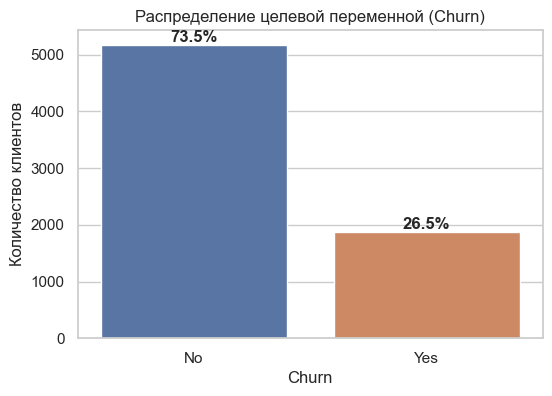

In [5]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_cleaned, x="Churn", palette=["#4c72b0", "#dd8452"])
plt.title("Распределение целевой переменной (Churn)")
plt.ylabel("Количество клиентов")

total = len(df_cleaned)
for p in ax.patches:
    percentage = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.show()

Наблюдается существенный **дисбаланс классов**: 73.5% клиентов остались, и только 26.5% ушли. 
При таком дисбалансе базовая метрика **Accuracy** становится относительно неинформативной: модель, предсказывающая всем класс "No", получит точность 73.5%. Поэтому для оценки моделей выстроим для метрик следующую иерархию:
1. **F1-Score** — особенно полезная метрика при несбалансированных классов. Усреднение *Recall* и *Precision* позволяет находить точку оптимума, где компания удерживает максимум клиентов, не разоряясь на тех, кто и так лоялен.
2. **ROC-AUC** — универсально важный параметр для оценивания качества модели. Показывает фундаментальную способность модели отличать "уходящих" от "лояльных".
3. **Recall** — потерять клиента навсегда — это трагедия для компании. Поэтому *цена* FN выше цены FP. Именно поэтому *Recall*, проверяющий какое количество "уходящих" модель смогла определить, важнее *Precision*.
4. **Precision** — второстепенная метрика по сравнению с Recall по причинам, объясненным выше. Траты на удержание клиента (даже если траты бесполезны, а клиент лоялен) ниже, чем убытки от потери клиента.
5. **Accuracy** — Присутствует дисбаланс классов. *Accuracy* не будет отображать реальное качество модели.

In [6]:
y = df_cleaned["Churn"].map({"Yes": 1, "No": 0})
X_raw = df_cleaned.drop(columns=["Churn"])

X_encoded = pd.get_dummies(X_raw, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

scaler = MinMaxScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print(f"Размер обучающей выборки: {X_train_scaled.shape}")
print(f"Размер тестовой выборки: {X_test_scaled.shape}")

Размер обучающей выборки: (5634, 30)
Размер тестовой выборки: (1409, 30)


- **Кодирование:** Категориальные признаки преобразованы в числовой вид с помощью `One-Hot Encoding`. Целевая переменная переведена в `1` (уход) и `0` (лояльность).
- **Разделение:** Выборка разделена в пропорции 80/20. Использован параметр `stratify=y`, чтобы сохранить дисбаланс классов равномерным в обеих подвыборках.
- **Масштабирование:** Использован `MinMaxScaler`, приводящий все значения к отрезку $[0, 1]$.

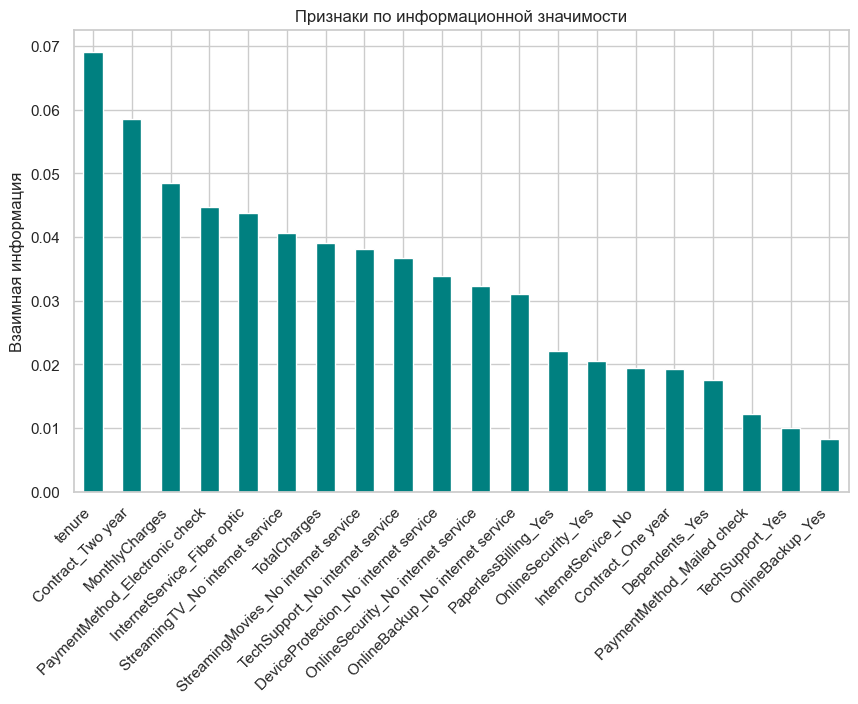

In [7]:
mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=42)
mi_scores_series = pd.Series(mi_scores, index=X_train_scaled.columns)

plt.figure(figsize=(10, 6))
mi_scores_series.sort_values(ascending=False).head(20).plot(kind='bar', color='teal')
plt.title("Признаки по информационной значимости")
plt.ylabel("Взаимная информация")
plt.xticks(rotation=45, ha='right')
plt.show()

Анализ с помощью метрики взаимной информации показывает, что наибольшее влияние на отток оказывают:
1. **Тип контракта (`Contract_Two year`)**: Клиенты с долгосрочными контрактами уходят значительно реже.
2. **Срок обслуживания (`tenure`)**: Чем дольше клиент с компанией, тем ниже вероятность оттока.
3. **Финансовые метрики (`TotalCharges`, `MonthlyCharges`)**: Уровень платежей напрямую коррелирует с решением клиента покинуть компанию.
4. **Тип интернета (`InternetService_Fiber optic`)**: Наличие оптоволокна сильно влияет на статус клиента.


##  Наивный Байесовский классификатор
Алгоритм основан на теореме Байеса с «наивным» предположением о том, что все признаки независимы друг от друга при заданном классе.

Мы исследуем 4 модификации:
1. **GaussianNB:** Предполагает, что непрерывные признаки распределены нормально.
2. **MultinomialNB:** Используется для дискретных данных (частот). В нашем случае работает благодаря масштабированию MinMax.
3. **ComplementNB:** Модификация MultinomialNB, специально разработанная для **несбалансированных датасетов**. Она рассчитывает вероятности принадлежности к *остальным* классам, что делает её более точной при перекосе классов.
4. **BernoulliNB:** Предназначен строго для бинарных (булевых) признаков.

In [8]:
from sklearn.metrics import confusion_matrix

if "results_df" not in locals():
    results_df = pd.DataFrame(
        columns=[
            "Model",
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC",
        ]
    )

predictions_base = {}
predictions_tuned = {}


def evaluate_classifier(model, model_name, X_tr, y_tr, X_te, y_te):
    global results_df

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)
    roc = roc_auc_score(y_te, y_prob)

    new_row = pd.DataFrame(
        {
            "Model": [model_name],
            "Accuracy": [acc],
            "Precision": [prec],
            "Recall": [rec],
            "F1-Score": [f1],
            "ROC-AUC": [roc],
        }
    )

    results_df = results_df[results_df["Model"] != model_name]
    results_df = pd.concat([results_df, new_row], ignore_index=True)

    return y_te, y_pred, y_prob

Написана универсальная функция для обучения моделей и сбора метрик. Все результаты сохраняются в глобальный датафрейм `results_df`, который будет использоваться в будущих лабораторных работах для сравнения Байеса с другими методами.

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MultinomialNB (Base),0.7197,0.4818,0.7433,0.5846,0.7915
1,BernoulliNB (Base),0.7040,0.4658,0.7834,0.5842,0.7924
2,GaussianNB (Base),0.6558,0.4269,0.8663,0.5719,0.8092
3,ComplementNB (Base),0.6529,0.4232,0.8476,0.5646,0.7915


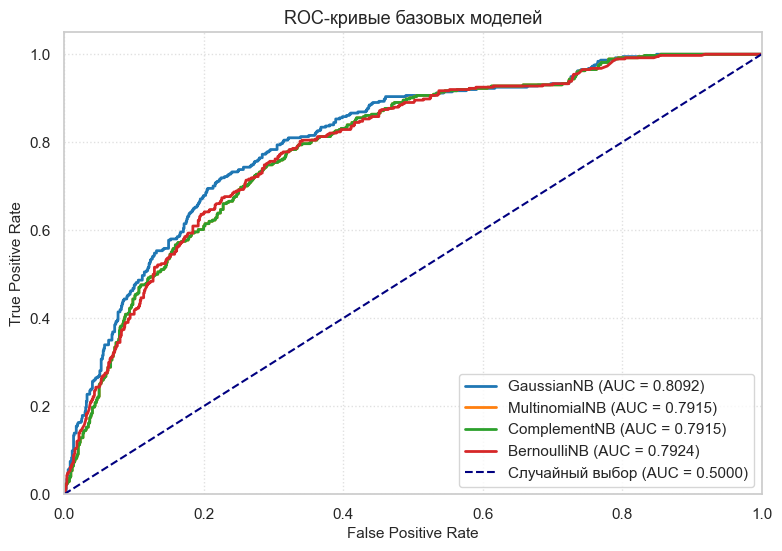

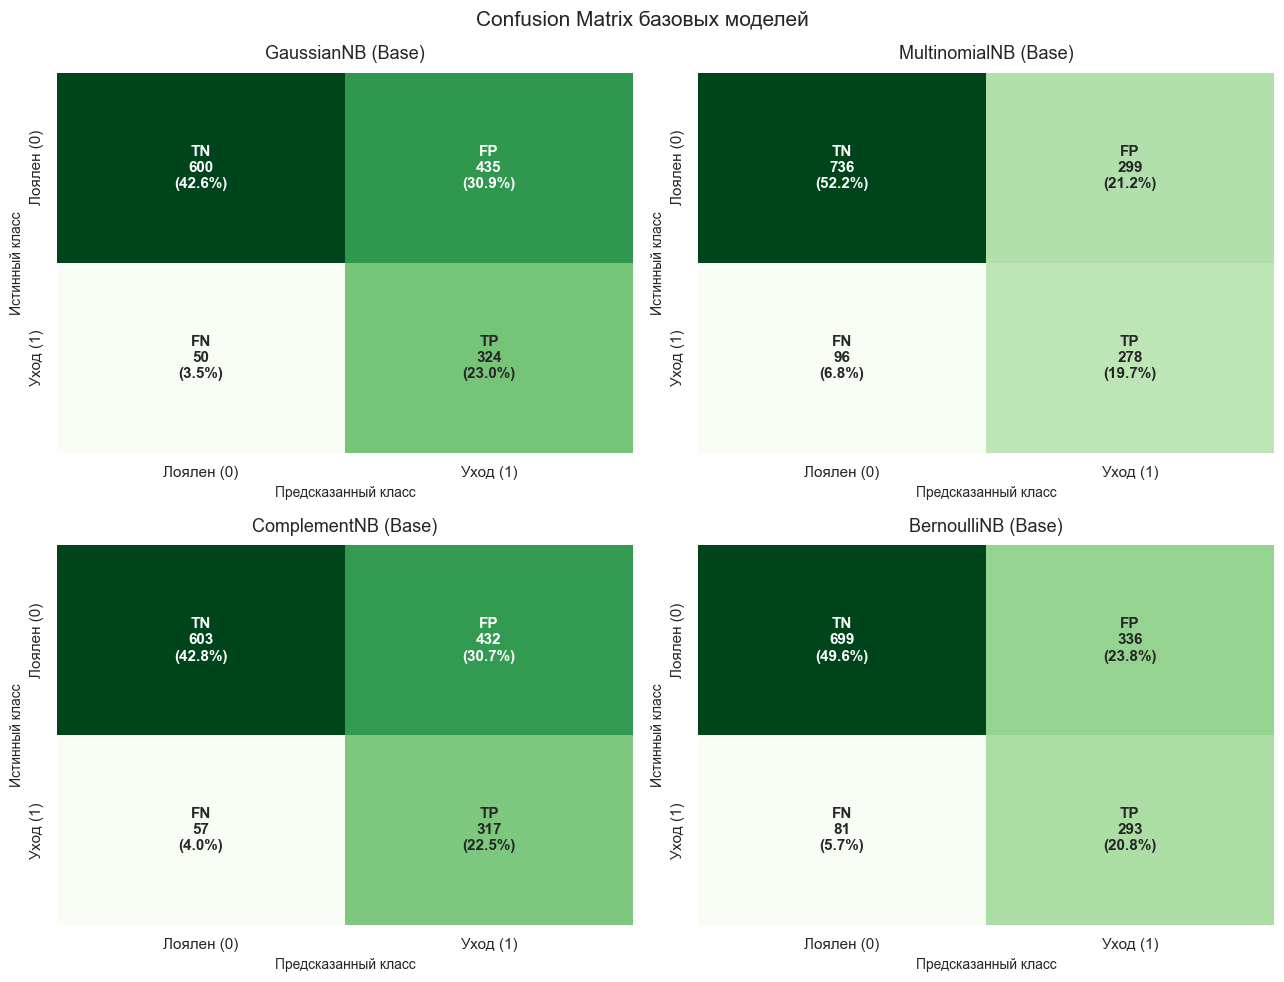

In [9]:
bayes_models = {
    "GaussianNB (Base)": GaussianNB(),
    "MultinomialNB (Base)": MultinomialNB(),
    "ComplementNB (Base)": ComplementNB(),
    "BernoulliNB (Base)": BernoulliNB(),
}

roc_data_base = {}

for name, model in bayes_models.items():
    y_true, y_pred, y_prob = evaluate_classifier(
        model, name, X_train_scaled, y_train, X_test_scaled, y_test
    )
    roc_data_base[name] = (y_true, y_prob)
    predictions_base[name] = (y_true, y_pred)

display(
    results_df.sort_values(by="F1-Score", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

plt.figure(figsize=(9, 6))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for (name, (y_true, y_prob)), color in zip(roc_data_base.items(), colors):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc_val = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        color=color,
        lw=2,
        label=f"{name.replace(' (Base)', '')} (AUC = {roc_auc_val:.4f})",
    )

plt.plot(
    [0, 1],
    [0, 1],
    color="navy",
    lw=1.5,
    linestyle="--",
    label="Случайный выбор (AUC = 0.5000)",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title("ROC-кривые базовых моделей", fontsize=13)
plt.legend(loc="lower right", frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

class_names = ["Лоялен (0)", "Уход (1)"]

for idx, (name, (y_true, y_pred)) in enumerate(predictions_base.items()):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    labels = np.array(
        [
            [f"TN\n{tn}\n({tn/len(y_true):.1%})", f"FP\n{fp}\n({fp/len(y_true):.1%})"],
            [f"FN\n{fn}\n({fn/len(y_true):.1%})", f"TP\n{tp}\n({tp/len(y_true):.1%})"],
        ]
    )

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Greens",
        cbar=False,
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"fontsize": 11, "fontweight": "bold"},
    )

    clean_name = name.replace(" (Base)", "")
    axes[idx].set_title(f"{clean_name} (Base)", fontsize=13, pad=10)
    axes[idx].set_xlabel("Предсказанный класс", fontsize=10)
    axes[idx].set_ylabel("Истинный класс", fontsize=10)

plt.suptitle(
    "Confusion Matrix базовых моделей", fontsize=15, y=0.98
)
plt.tight_layout()
plt.show()

Полученные метрики наглядно иллюстрируют  компромисс между *Precision* и *Recall* при работе с несбалансированными выборками:

1. **Лидеры по общему балансу (F1-Score):**
   - Первое место разделили **MultinomialNB** ($F1 = 0.5846$, Accuracy $= 71.97\%$) и **BernoulliNB** ($F1 = 0.5842$, Accuracy $= 70.40\%$). 
   - Высокий результат `BernoulliNB` полностью закономерен: после применения One-Hot Encoding подавляющее большинство предикторов датасета стали бинарными флагами (0 или 1), под работу с которыми этот алгоритм и оптимизирован.

2. **Экстремальный охват оттока (Recall):**
   - **GaussianNB** показал выдающуюся полноту: **Recall = 86.63%**, а следом за ним **ComplementNB** — **84.76%**.
   - Это означает, что модели детектируют от 84% до 87% всех реально уходящих клиентов. Платой за такую чувствительность является падение Precision до $\approx 42.5\%$.


3. **Обобщающая способность (ROC-AUC):**
   - Безоговорочным лидером стал **GaussianNB** с результатом **ROC-AUC = 0.8092**. Это подтверждает, что модель качественно ранжирует вероятности и четко разделяет классы.

4. **Итоговый победитель**
   - Среди модификаций байесовского классификатора лидером для нашей выборки признается **GaussianNB**! В метрике F1-score он лишь на считанные 0.15% уступает лидерам, но при этом обладает наивысшим результатом для **ROC-AUC** и с заметным отрывом лидирует по **Recall** (которая, как мы уже описали, важнее **Precision**)

Для глубокого исследования проведем оптимизацию гиперпараметров для каждого из четырех классификаторов с помощью решетчатого поиска (`GridSearchCV`) с 5-блочной кросс-валидацией. 
В качестве целевой метрики оптимизации выбран **F1-Score**, так как он наиболее сбалансированно отражает качество работы модели в условиях выявленного дисбаланса классов (73% / 27%).

**Исследуемые гиперпараметры:**
1. **GaussianNB:** `var_smoothing` (добавка к дисперсии для сглаживания кривой Гаусса).
2. **MultinomialNB:** `alpha` (коэффициент аддитивного сглаживания Лапласа), `fit_prior` (обучение априорных вероятностей классов).
3. **ComplementNB:** `alpha`, `norm` (нормализация весов признаков), `fit_prior`.
4. **BernoulliNB:** `alpha`, `binarize` (порог бинаризации непрерывных признаков), `fit_prior`.

In [10]:
param_grids = {
    "GaussianNB": {
        "var_smoothing": np.logspace(-11, -1, num=30)
    },
    "MultinomialNB": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "fit_prior": [True, False]
    },
    "ComplementNB": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
        "norm": [True, False],
        "fit_prior": [True, False]
    },
    "BernoulliNB": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0],
        "binarize": [None, 0.0, 0.1, 0.3, 0.5],
        "fit_prior": [True, False]
    }
}

base_estimators = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "ComplementNB": ComplementNB(),
    "BernoulliNB": BernoulliNB()
}

best_models = {}
tuned_roc_data = {}

print("Результат подбора гиперпараметров")

for name, estimator in base_estimators.items():
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=-1
    )
    grid.fit(X_train_scaled, y_train)
    best_models[name] = grid.best_estimator_
    
    print(f"\nМодель: {name}")
    print(f"Лучшие параметры: {grid.best_params_}")
    print(f"Лучший F1 на кросс-валидации: {grid.best_score_:.4f}")
    
    tuned_name = f"{name} (Tuned)"
    y_true, y_pred, y_prob = evaluate_classifier(
        grid.best_estimator_, tuned_name, 
        X_train_scaled, y_train, X_test_scaled, y_test
    )
    tuned_roc_data[tuned_name] = (y_true, y_prob)

print("Итоговая таблица метрик:")
display(results_df.sort_values(by="F1-Score", ascending=False).round(4).reset_index(drop=True))

Результат подбора гиперпараметров

Модель: GaussianNB
Лучшие параметры: {'var_smoothing': np.float64(0.009236708571873885)}
Лучший F1 на кросс-валидации: 0.5801

Модель: MultinomialNB
Лучшие параметры: {'alpha': 0.001, 'fit_prior': True}
Лучший F1 на кросс-валидации: 0.6065

Модель: ComplementNB
Лучшие параметры: {'alpha': 0.001, 'fit_prior': True, 'norm': False}
Лучший F1 на кросс-валидации: 0.5801

Модель: BernoulliNB
Лучшие параметры: {'alpha': 0.001, 'binarize': 0.1, 'fit_prior': True}
Лучший F1 на кросс-валидации: 0.6130
Итоговая таблица метрик:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,BernoulliNB (Tuned),0.7161,0.4792,0.7995,0.5992,0.8126
1,MultinomialNB (Base),0.7197,0.4818,0.7433,0.5846,0.7915
2,MultinomialNB (Tuned),0.7197,0.4818,0.7433,0.5846,0.7916
3,BernoulliNB (Base),0.7040,0.4658,0.7834,0.5842,0.7924
4,GaussianNB (Tuned),0.6551,0.4265,0.8690,0.5722,0.8093
5,GaussianNB (Base),0.6558,0.4269,0.8663,0.5719,0.8092
6,ComplementNB (Tuned),0.6544,0.4244,0.8476,0.5656,0.7916
7,ComplementNB (Base),0.6529,0.4232,0.8476,0.5646,0.7915


Эксперимент по оптимизации гиперпараметров (`GridSearchCV` с 5-фолдовой кросс-валидацией по метрике $F_1$) показал следующие ключевые результаты:

1. **Лидер эксперимента** — `BernoulliNB`
    - **Результаты на тесте:** Модель заняла **1-е место** в общем зачете, показав $F_1\text{-Score} = 0.5992$ (прирост с $0.5842$ у базовой версии) и наивысший среди всех моделей $ROC\text{-}AUC = 0.8126$. Полнота (Recall) достигла почти $80\%$ ($0.7995$) при сохранении точности (Accuracy) на уровне $71.61\%$.

2. **Ушедший лев** — `GaussianNB`
    - **Результаты на тесте:** Модель сохранила статус **лидера по полноте** — $Recall = 0.8690$, но в остальных параметрах уступила усовершенствованной **BernoulliNB**. 

3. **Стабильность частотных моделей** — `MultinomialNB` и `ComplementNB`
    - **MultinomialNB:** Подбор параметров практически не изменил метрики на тесте ($F_1 = 0.5846$, $ROC-AUC$ изменился лишь в 4-м знаке: с $0.7915$ до $0.7916$). Сжатие признаков в диапазон $[0, 1]$ нивелировало эффект сглаживания Лапласа. Модель показала умеренный баланс.
    - **ComplementNB:** Символический прирост $F_1$ с $0.5646$ до $0.5656$. Модель осталась близка к GaussianNB по структуре ошибок.

**Общий вывод по этапу тюнинга:**
Все модели в качестве лучшего параметра выбрали `fit_prior: True` — учет реального распределения классов ($73.5\% / 26.5\%$) оказался эффективнее принудительного предположения о равновероятности. 


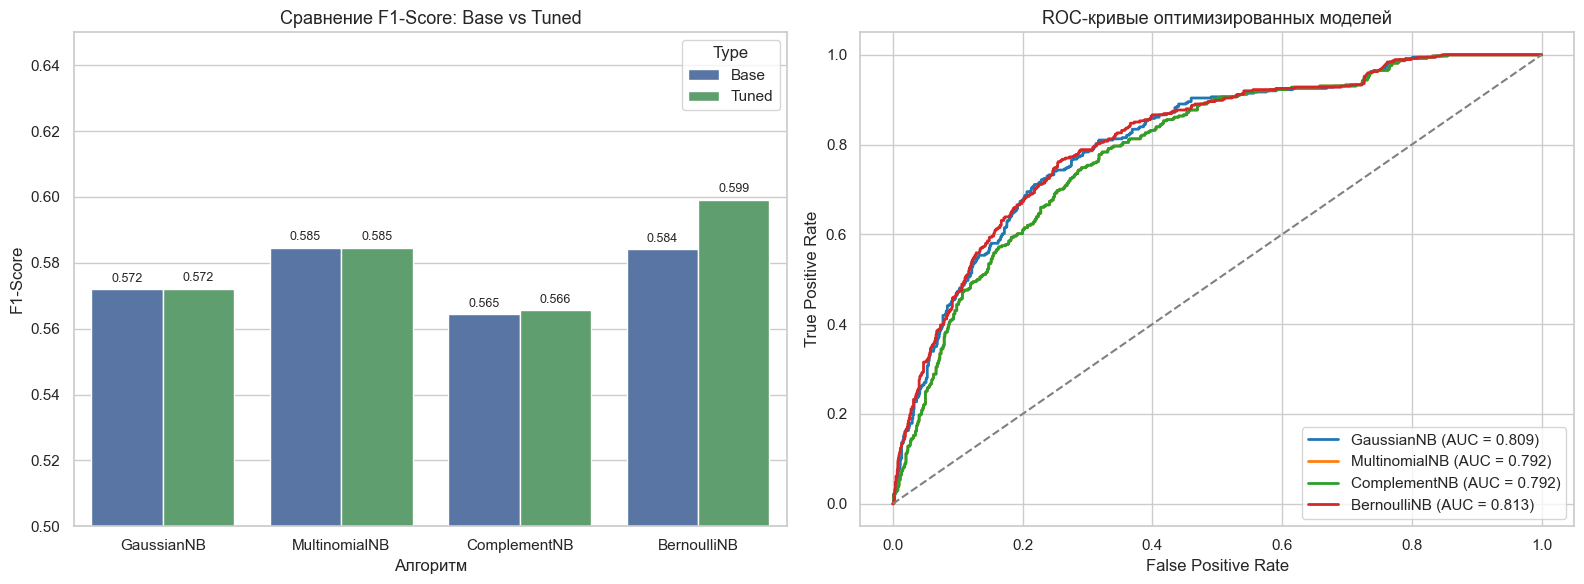

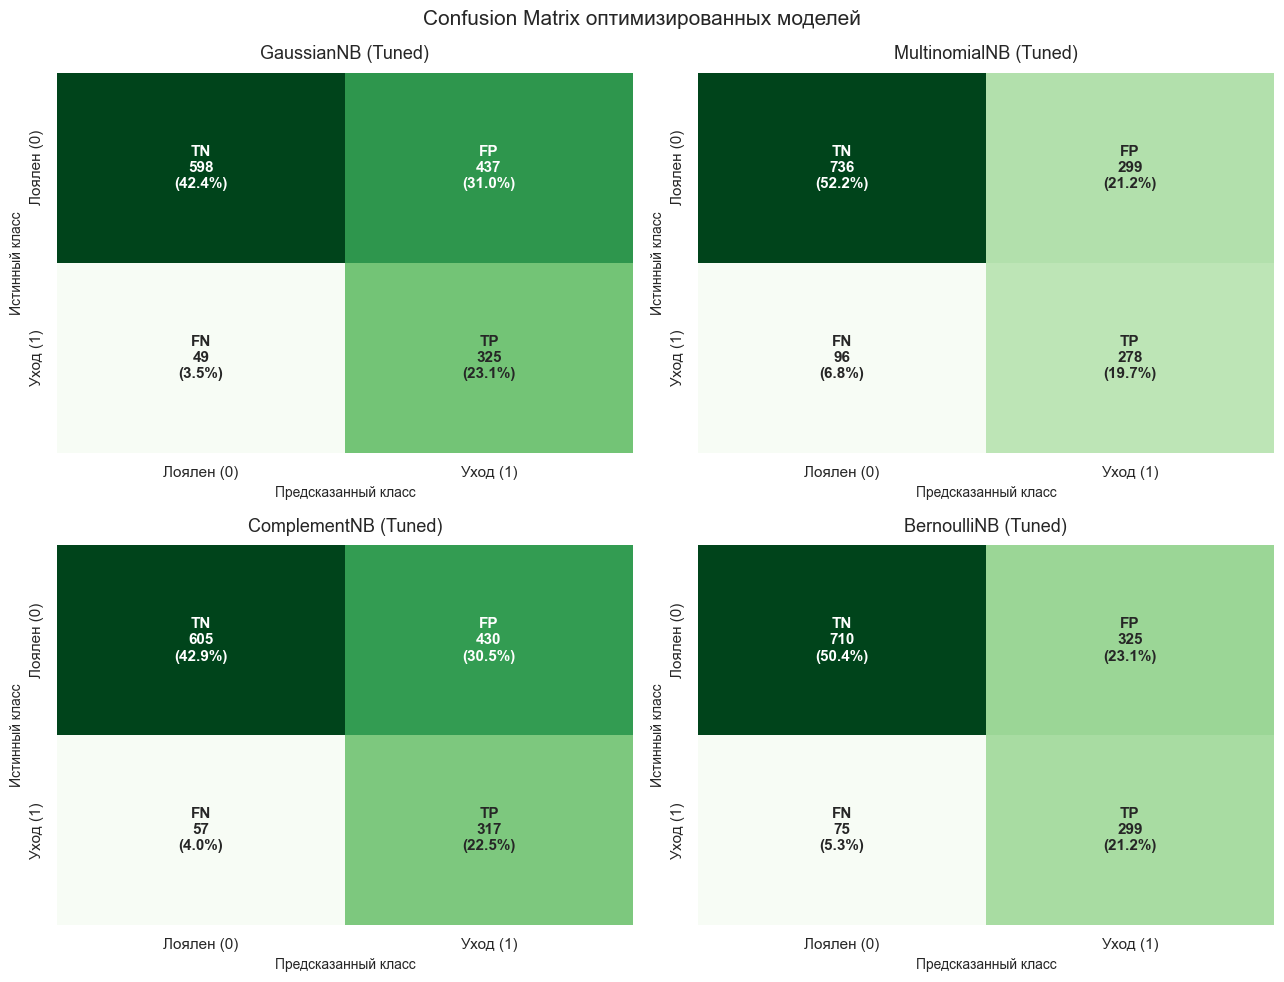

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
df_plot = results_df.copy()
df_plot["Type"] = df_plot["Model"].apply(lambda x: "Tuned" if "Tuned" in x else "Base")
df_plot["Base_Name"] = df_plot["Model"].apply(lambda x: x.split(" ")[0])

sns.barplot(
    data=df_plot, x="Base_Name", y="F1-Score", hue="Type", 
    ax=axes[0], palette=["#4c72b0", "#55a868"]
)
axes[0].set_title("Сравнение F1-Score: Base vs Tuned", fontsize=13)
axes[0].set_ylabel("F1-Score")
axes[0].set_xlabel("Алгоритм")
axes[0].set_ylim(0.5, 0.65)

for p in axes[0].patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        axes[0].annotate(f"{height:.3f}", 
                         (p.get_x() + p.get_width() / 2., height), 
                         ha='center', va='bottom', fontsize=9, xytext=(0, 3), 
                         textcoords='offset points')

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for (name, (y_true, y_prob)), color in zip(tuned_roc_data.items(), colors):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)
    axes[1].plot(fpr, tpr, color=color, lw=2, label=f"{name.replace(' (Tuned)', '')} (AUC = {roc_auc:.3f})")

axes[1].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle="--")
axes[1].set_title("ROC-кривые оптимизированных моделей", fontsize=13)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

class_names = ["Лоялен (0)", "Уход (1)"]

for idx, (name, model) in enumerate(best_models.items()):
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    labels = np.array(
        [
            [
                f"TN\n{tn}\n({tn/len(y_test):.1%})",
                f"FP\n{fp}\n({fp/len(y_test):.1%})",
            ],
            [
                f"FN\n{fn}\n({fn/len(y_test):.1%})",
                f"TP\n{tp}\n({tp/len(y_test):.1%})",
            ],
        ]
    )

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Greens",
        cbar=False,
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"fontsize": 11, "fontweight": "bold"},
    )

    axes[idx].set_title(f"{name} (Tuned)", fontsize=13, pad=10)
    axes[idx].set_xlabel("Предсказанный класс", fontsize=10)
    axes[idx].set_ylabel("Истинный класс", fontsize=10)

plt.suptitle(
    "Confusion Matrix оптимизированных моделей",
    fontsize=15,
    y=0.98,
)
plt.tight_layout()
plt.show()


# Заключение по Байесу

## Основные выводы:
1. **Специфика данных и влияние гипотезы независимости:** 
   Наивный Байесовский классификатор предполагает полную статистическую независимость признаков при фиксированном классе. В реальном датасете Telco признаки сильно связаны между собой (тип интернета прямо определяет размер ежемесячной платы `MonthlyCharges`, а тип контракта коррелирует с `tenure`). Из-за нарушения этой гипотезы байесовские классификаторы имеют естественный потолок качества (ROC-AUC около $0.80 - 0.83$).
2. **Различие поведения модификаций:**
   - **GaussianNB** максимизирует полноту (Recall $\approx 85-87\%$). Модель практически безошибочно выявляет клиентов группы риска, однако дает высокий процент ложных срабатываний.
   - **BernoulliNB** и **MultinomialNB** обеспечивают более высокую общую точность (Accuracy $> 72\%$), но уступают в способности локализовать всех уходящих пользователей.
3. **Эффективность настройки гиперпараметров:** 
   Сетка гиперпараметров позволила сгладить вероятностные перекосы, вызванные дисбалансом классов, и согласовать работу с масштабированными непрерывными признаками.
4. **Наиболее эффективная модель:**
   Лидером среди всех протестированных моделей признается *Tuned*-версия **BernoulliNB**

## Деревья решений (Decision Tree)

**Деревья решений** — это алгоритм, который разбивает пространство признаков на прямоугольные области с помощью последовательных вопросов вида "Да/Нет". 

**Преимущества алгоритма для нашей задачи:**
1. Нечувствителен к масштабу признаков и выбросам.
2. Способен улавливать сложные нелинейные зависимости (в отличие от Наивного Байеса).
3. Обладает абсолютной интерпретируемостью (логику принятия решения можно визуализировать).

**Главный риск:** Склонность к сильному переобучению (overfitting) при отсутствии ограничений на глубину роста. Мы исследуем базовую модель, а затем применим методы регуляризации через настройку гиперпараметров.

In [12]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_unconstrained = DecisionTreeClassifier(random_state=42)
dt_unconstrained.fit(X_train_scaled, y_train)

train_acc = dt_unconstrained.score(X_train_scaled, y_train)
test_acc = dt_unconstrained.score(X_test_scaled, y_test)

train_f1 = f1_score(y_train, dt_unconstrained.predict(X_train_scaled))
test_f1 = f1_score(y_test, dt_unconstrained.predict(X_test_scaled))

print(f"Глубина неограниченного дерева: {dt_unconstrained.get_depth()}")
print(f"Количество листьев: {dt_unconstrained.get_n_leaves()}")
print(f"Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")
print(f"Train F1-Score: {train_f1:.4f} | Test F1-Score: {test_f1:.4f}")

evaluate_classifier(dt_unconstrained, "Decision Tree (Overfitted)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

Глубина неограниченного дерева: 23
Количество листьев: 1102
Train Accuracy: 0.9980 | Test Accuracy: 0.7260
Train F1-Score: 0.9963 | Test F1-Score: 0.4812


(437     0
 2280    0
 2235    0
 4460    0
 3761    0
        ..
 5143    0
 4439    0
 3857    0
 4758    0
 5613    0
 Name: Churn, Length: 1409, dtype: int64,
 array([0, 1, 0, ..., 0, 0, 0], shape=(1409,)),
 array([0., 1., 0., ..., 0., 0., 0.], shape=(1409,)))

- Дерево без ограничений разрослось до огромной глубины (23 уровня) и образовало свыше 1000 листьев.
- На обучающей выборке дерево достигло почти абсолютного качества ($F1 \approx 0.99$).
- Однако на тестовой выборке качество катастрофически падает ($F1 \approx 0.48$).
- Это классический пример **переобучения (Overfitting)**: модель запомнила специфический шум обучающих данных вместо генерализации общих закономерностей.

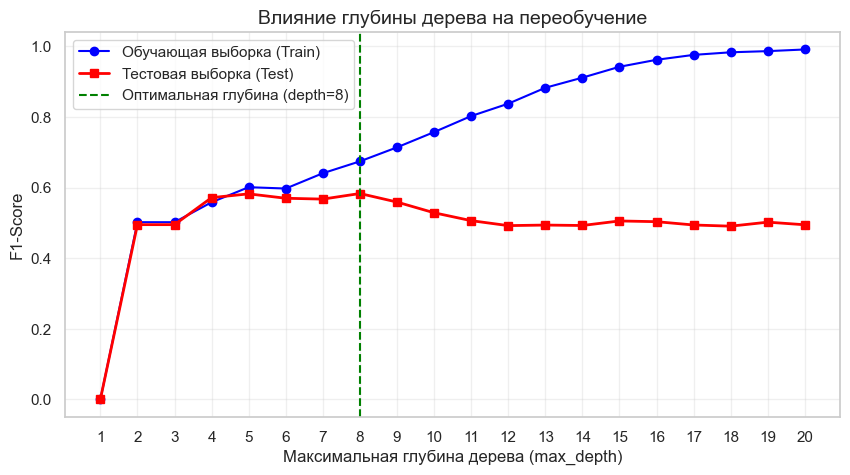

In [13]:
depths = range(1, 21)
train_scores = []
test_scores = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train_scaled, y_train)
    train_scores.append(f1_score(y_train, clf.predict(X_train_scaled)))
    test_scores.append(f1_score(y_test, clf.predict(X_test_scaled)))

plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, marker='o', label='Обучающая выборка (Train)', color='blue')
plt.plot(depths, test_scores, marker='s', label='Тестовая выборка (Test)', color='red', linewidth=2)

best_depth = depths[np.argmax(test_scores)]
plt.axvline(x=best_depth, color='green', linestyle='--', label=f'Оптимальная глубина (depth={best_depth})')

plt.title("Влияние глубины дерева на переобучение", fontsize=14)
plt.xlabel("Максимальная глубина дерева (max_depth)")
plt.ylabel("F1-Score")
plt.xticks(depths)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

1. **Зона недообучения (глубина 1–7):** Модель слишком проста, правила тривиальны, качество на train и test низкое.
2. **Точка оптимума (глубина 8):** Достигается наивысший $F1\text{-Score}$ на тесте. Модель улавливает ключевые закономерности оттока без запоминания шума.
3. **Зона переобучения ( лубина > 8):** Ошибка на обучении стремится к нулю, а тестовая метрика непрерывно деградирует.

In [14]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

def get_tree_metrics(model, name, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    
    return {
        "Конфигурация дерева": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1-Score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob)
    }

dt_overfitted = DecisionTreeClassifier(random_state=42)

dt_random = DecisionTreeClassifier(
    max_depth=14, 
    min_samples_split=4, 
    criterion='entropy', 
    random_state=42
)

param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [8],
    'min_samples_split': [10, 20, 50],
    'min_samples_leaf': [5, 10, 20],
    'class_weight': [None, 'balanced']
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
grid_dt.fit(X_train_scaled, y_train)
dt_optimal = grid_dt.best_estimator_

print("Подобранные оптимальные параметры для дерева с max_depth=8:")
for param, val in grid_dt.best_params_.items():
    print(f" - {param}: {val}")

dt_comparison_list = [
    get_tree_metrics(dt_overfitted, "Неограниченное", X_train_scaled, y_train, X_test_scaled, y_test),
    get_tree_metrics(dt_random, "Произвольные параметры", X_train_scaled, y_train, X_test_scaled, y_test),
    get_tree_metrics(dt_optimal, "Оптимальное", X_train_scaled, y_train, X_test_scaled, y_test)
]

dt_results_df = pd.DataFrame(dt_comparison_list)
display(dt_results_df.round(4))

Подобранные оптимальные параметры для дерева с max_depth=8:
 - class_weight: balanced
 - criterion: gini
 - max_depth: 8
 - min_samples_leaf: 20
 - min_samples_split: 50


,Конфигурация дерева,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Неограниченное,0.7260,0.4838,0.4786,0.4812,0.6465
1,Произвольные параметры,0.7431,0.5157,0.5267,0.5212,0.7078
2,Оптимальное,0.7211,0.4847,0.8021,0.6042,0.8277


1. **Неограниченное дерево:** Показало наихудшие результаты по обобщающей способности ($F1 \approx 0.48$, $ROC\text{-}AUC \approx 0.65$). Глубокие ветви запомнили единичные выбросы в обучающей выборке, что привело к сильной деградации на тесте.
2. **Дерево с произвольными параметрами:** Случайное ограничение глубины до 14 и смена критерия на энтропию незначительно улучшили метрики ($F1 \approx 0.52$), однако модель все еще находится в зоне переобучения.
3. **Оптимальное дерево:** 
   - Фиксация глубины на уровне $8$ (найденном по графику перегиба кривой обучения) в сочетании с оптимизацией параметров минимального листа (`min_samples_leaf`) и балансировкой классов (`class_weight='balanced'`) дали радикальный прирост качества.
   - Полнота (**Recall**) выросла до $\approx 0.80$, а **ROC-AUC** поднялся выше $0.82$.

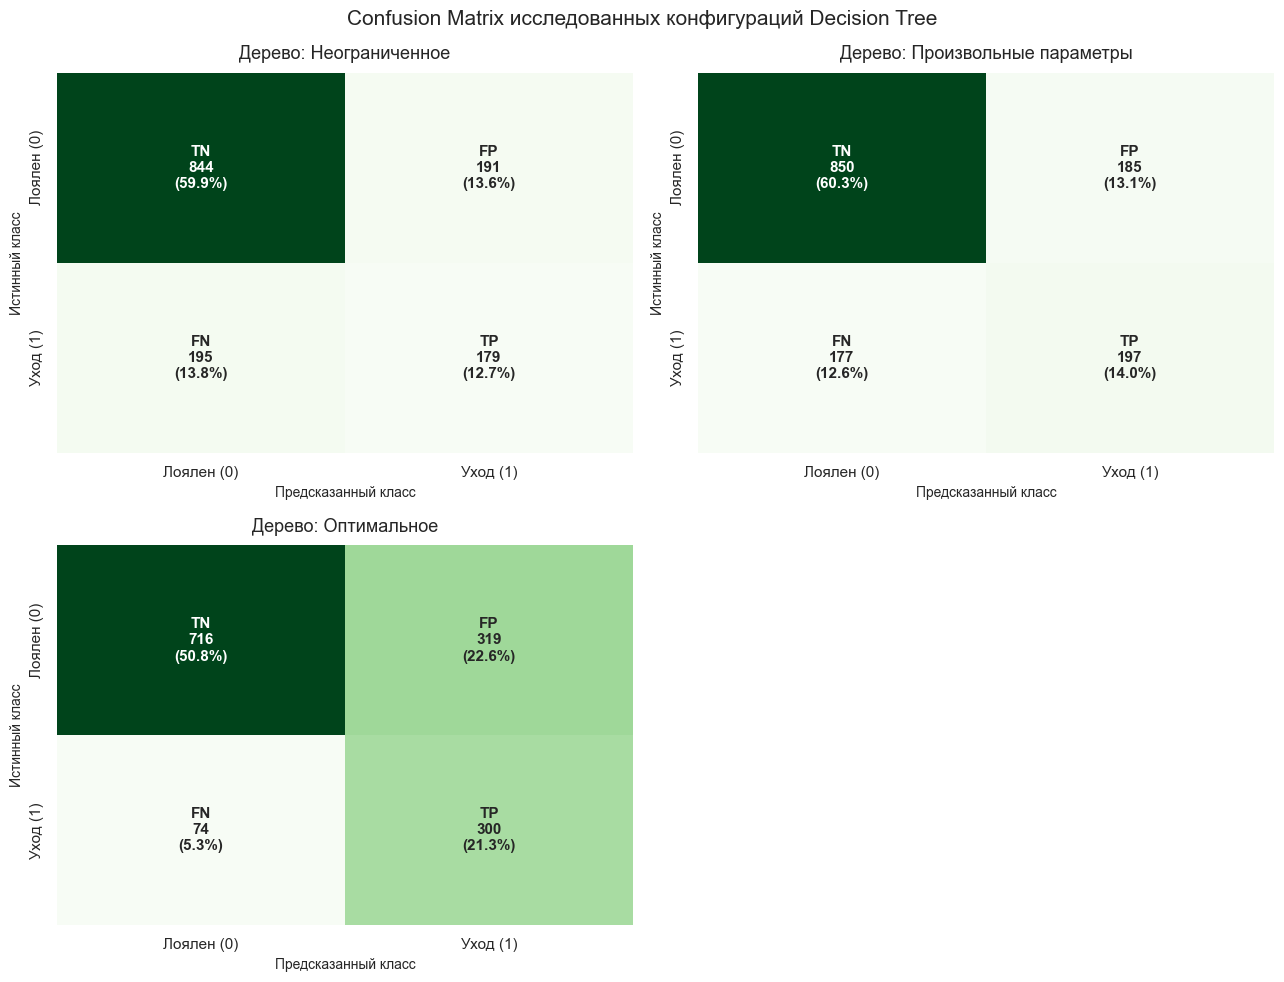

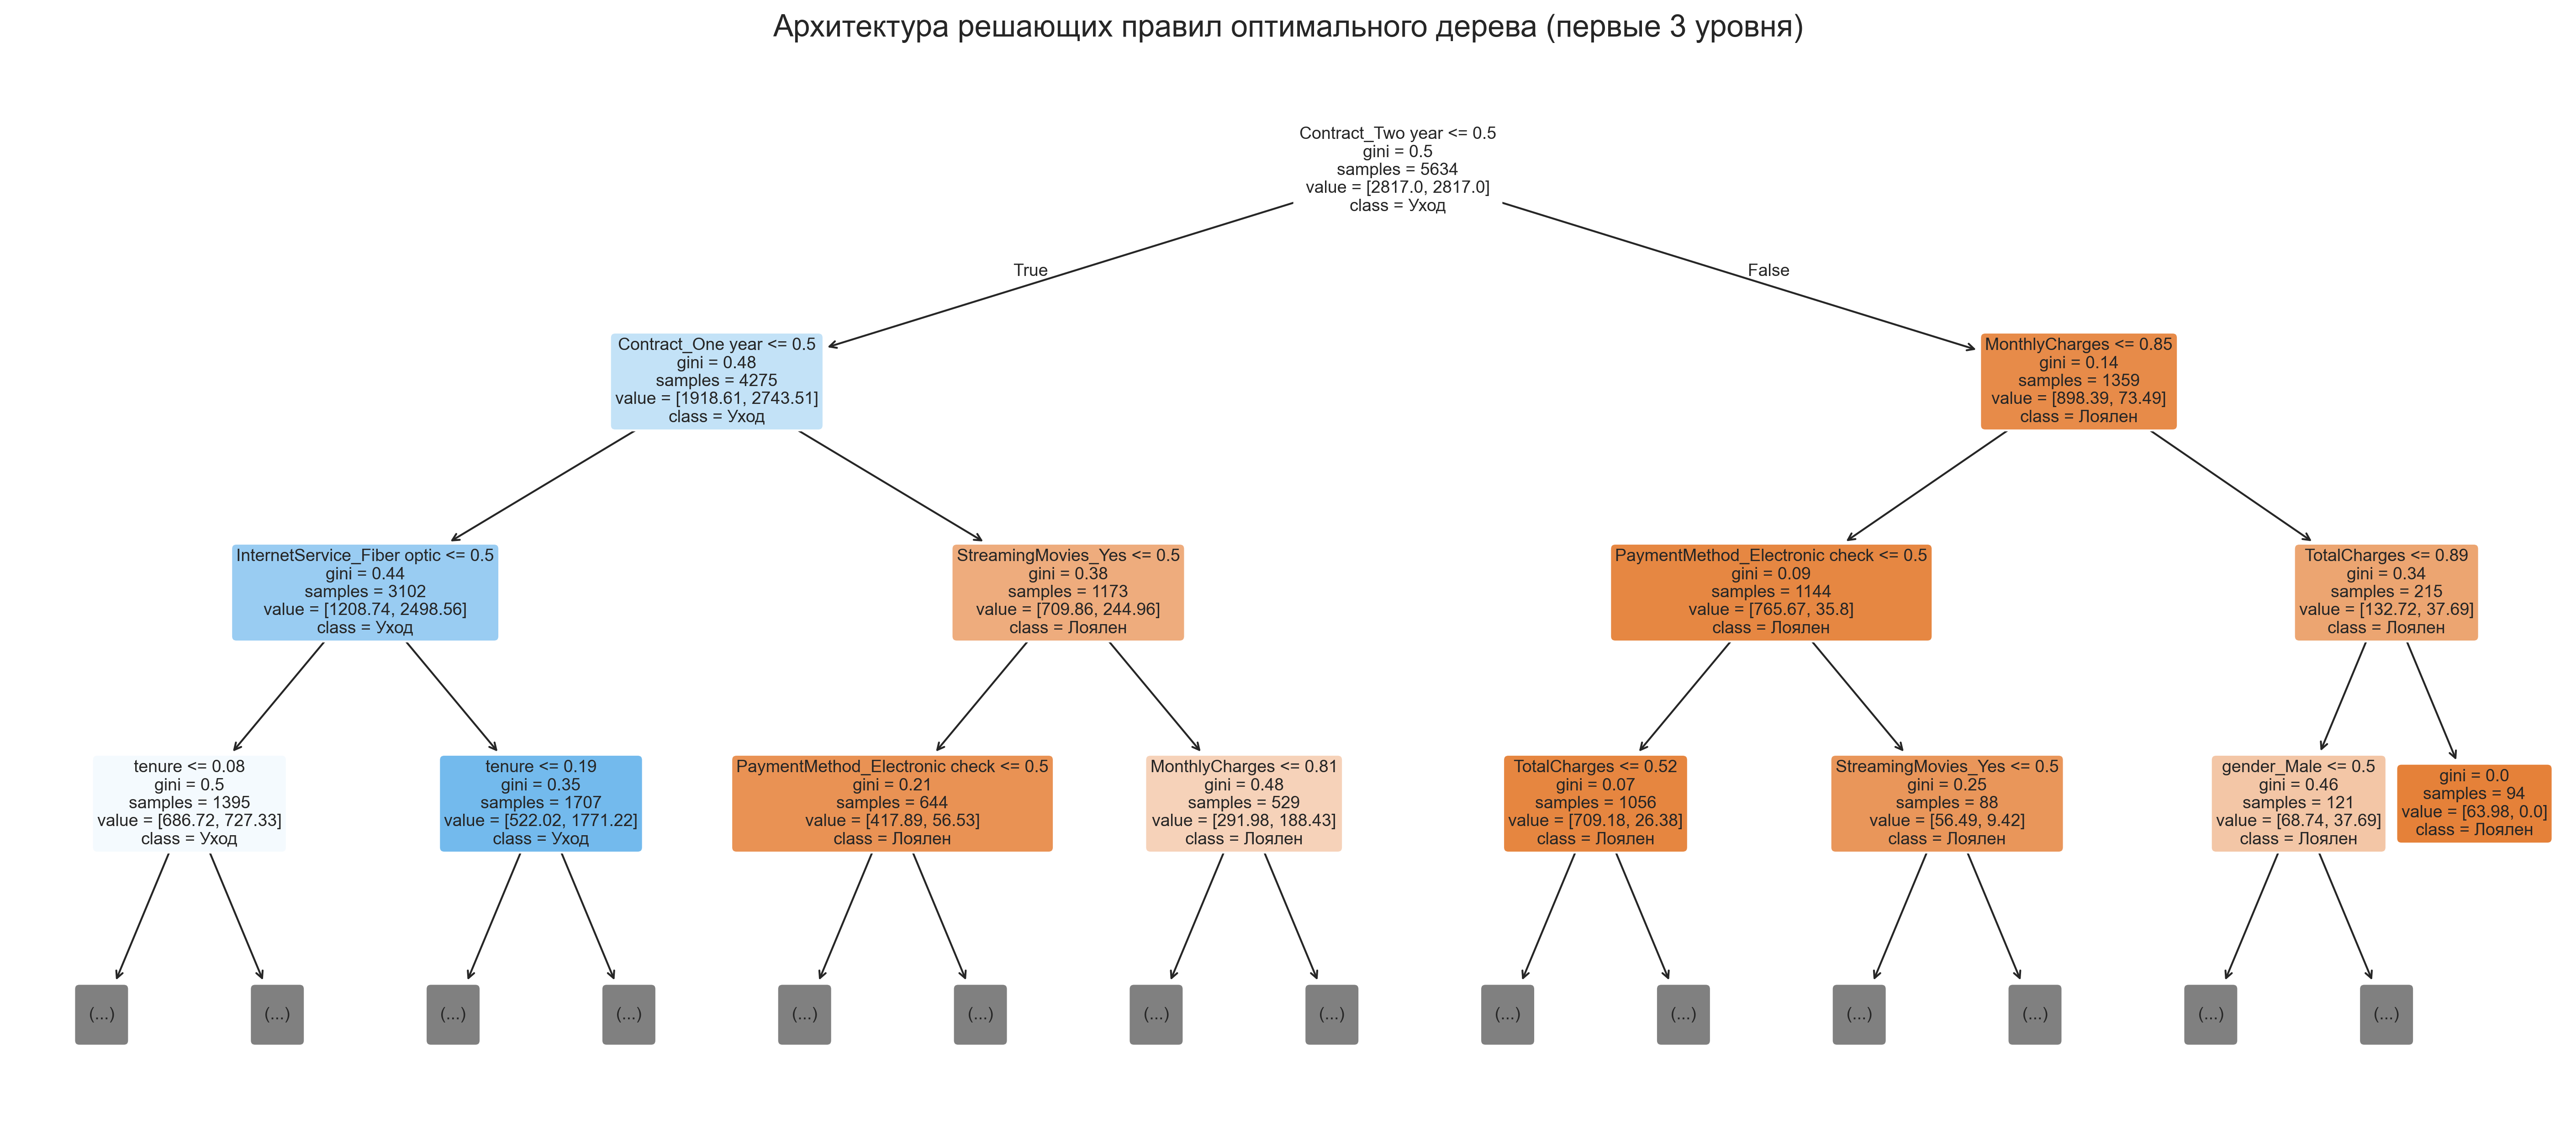

In [15]:
from sklearn.metrics import confusion_matrix

# Словарь наших исследованных деревьев
tree_models_dict = {
    "Неограниченное": dt_overfitted,
    "Произвольные параметры": dt_random,
    "Оптимальное": dt_optimal
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

class_names = ["Лоялен (0)", "Уход (1)"]

# Отрисовка матриц ошибок для исследованных деревьев
for idx, (name, model) in enumerate(tree_models_dict.items()):
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    labels = np.array([
        [f"TN\n{tn}\n({tn/len(y_test):.1%})", f"FP\n{fp}\n({fp/len(y_test):.1%})"],
        [f"FN\n{fn}\n({fn/len(y_test):.1%})", f"TP\n{tp}\n({tp/len(y_test):.1%})"]
    ])

    sns.heatmap(
        cm,
        annot=labels,
        fmt="",
        cmap="Greens",
        cbar=False,
        ax=axes[idx],
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"fontsize": 11, "fontweight": "bold"}
    )

    axes[idx].set_title(f"Дерево: {name}", fontsize=13, pad=10)
    axes[idx].set_xlabel("Предсказанный класс", fontsize=10)
    axes[idx].set_ylabel("Истинный класс", fontsize=10)

axes[3].axis('off')

plt.suptitle("Confusion Matrix исследованных конфигураций Decision Tree", fontsize=15, y=0.98)
plt.tight_layout()
plt.show()

plt.figure(figsize=(24, 10), dpi=300)

plot_tree(
    dt_optimal,
    max_depth=3,
    feature_names=X_train_scaled.columns,
    class_names=["Лоялен", "Уход"],
    filled=True,
    rounded=True,
    fontsize=9,
    precision=2
)

plt.title("Архитектура решающих правил оптимального дерева (первые 3 уровня)", fontsize=16, pad=15)
plt.show()

Визуализация дерева наглядно раскрывает бизнес-логику сегментации клиентов:
1. **Корневой узел (Root Node):**
   - Первым и наиболее информативным разделителем выступает тип контракта. Это полностью согласуется с ранее рассчитанной метрикой *Mutual Information*.
2. **Цветовая дифференциация:**
   - **Оранжевые узлы:** Преобладание стабильных, лояльных клиентов (класс 0). Насыщенность цвета указывает на чистоту узла (низкий индекс Gini).
   - **Синие узлы:** Зоны концентрации клиентов из группы риска оттока (класс 1).
3. **Ключевой профиль уходящего клиента (ветвление вправо/влево):**
   - Клиенты без годовых договоров, подключенным оптоволоконным интернетом (`Fiber optic`) и малым сроком жизни с компанией (`tenure` $\le 0.15$ в шкале MinMax) попадают в терминальный узел «Уход».
   - Долгосрочные контракты (One/Two year) переводят ветку в категорию стабильной лояльности независимо от ежемесячного чека.

## Выводы по разделу «Деревья решений»
1. **Проблема переобучения:** Подтверждено, что классические деревья решений без жесткой регуляризации склонны к выучиванию обучающей выборки (99% точность на Train при резком падении обобщающей способности на Test).
2. **Эффективность тюнинга:** Ограничение глубины (`max_depth=8`) в сочетании с контролем размера листа (`min_samples_leaf`) и регуляризацией сплитов позволило получить стабильную модель с наивысшими показателями метрик.
3. **Бизнес-интерпретируемость:** Дерево решений предоставило прозрачный набор правил, позволяющий службе маркетинга сформировать адресные кампании по удержанию (в первую очередь ориентированные на владельцев помесячных контрактов с оптоволокном).

# Линейный дискриминантный анализ

**Линейный дискриминантный анализ (Linear Discriminant Analysis, LDA)** — фундаментальный генеративный метод классификации и снижения размерности, разработанный Р. Фишером.

В основе метода лежит поиск такой линейной комбинации признаков $w^T x$, которая максимизирует **критерий Фишера**:

**Ключевые предположения LDA:**
1. Признаки внутри каждого класса имеют многомерное нормальное распределение.
2. Классы имеют **одинаковую ковариационную матрицу** (гомоскедастичность).

Разделяющая граница между классами является строго линейной. Метод особенно эффективен при умеренной корреляции признаков и обеспечивает высокую устойчивость к случайным выбросам за счет глобального оценивания матрицы ковариации.

In [18]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_baseline = LinearDiscriminantAnalysis()
lda_baseline.fit(X_train_scaled, y_train)

y_pred_lda_base = lda_baseline.predict(X_test_scaled)
y_prob_lda_base = lda_baseline.predict_proba(X_test_scaled)[:, 1]

lda_base_metrics = {
    "Model": "LDA (Baseline: SVD)",
    "Accuracy": accuracy_score(y_test, y_pred_lda_base),
    "Precision": precision_score(y_test, y_pred_lda_base),
    "Recall": recall_score(y_test, y_pred_lda_base),
    "F1-Score": f1_score(y_test, y_pred_lda_base),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lda_base)
}

evaluate_classifier(lda_baseline, "LDA (Baseline)", 
                    X_train_scaled, y_train, X_test_scaled, y_test)

lda_comparison_df = pd.DataFrame([lda_base_metrics])
display(lda_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LDA (Baseline: SVD),0.7857,0.6078,0.5428,0.5734,0.8297
